# Envirionment Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
!pip install -q transformers datasets accelerate sentencepiece evaluate sentence-transformers faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 70.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 89.6 MB/s eta 0:00:00:00:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires 

In [4]:
from transformers import logging

logging.set_verbosity_warning()   # only important warnings

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re
from wordcloud import WordCloud

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, GroupKFold
from lightgbm import LGBMClassifier, LGBMRanker

from scipy.sparse import hstack
from tqdm import tqdm
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from scipy.special import softmax

import torch

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForMultipleChoice,
    TrainingArguments,
    Trainer
)

from sklearn.model_selection import train_test_split

import evaluate

from tqdm.auto import tqdm

from sentence_transformers import (
    SentenceTransformer,
    CrossEncoder
)

import faiss

import wandb

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

## Experiment Tracking (Weights & Biases)

In [4]:
PROJECT_NAME = "21f3002441-t22026"

In [5]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("WANDB_TOKEN")

In [6]:
wandb.login(key=secret_value_0)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 21f3002441 (21f3002441-dl-genai-project) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

# Data Importing

In [7]:
train_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
submission_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv')

# Exploratory Data Analysis

In [8]:
train_data = train_df.copy()
test_data = test_df.copy()
submission_data = submission_df.copy()

In [9]:
print("Dataset preview : \n")
train_data.head()

Dataset preview : 



,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [10]:
print(f"Train data size : {train_data.shape}")
print(f"Test data size : {test_data.shape}")

Train data size : (2000, 8)
Test data size : (500, 7)


In [11]:
train_data.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

## Answer Distribution

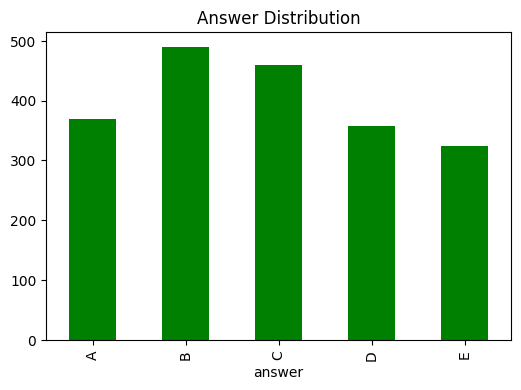

In [14]:
train_data["answer"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6,4), 
    color='g'
)
plt.title("Answer Distribution")
plt.show()

## Prompt Length Distributions

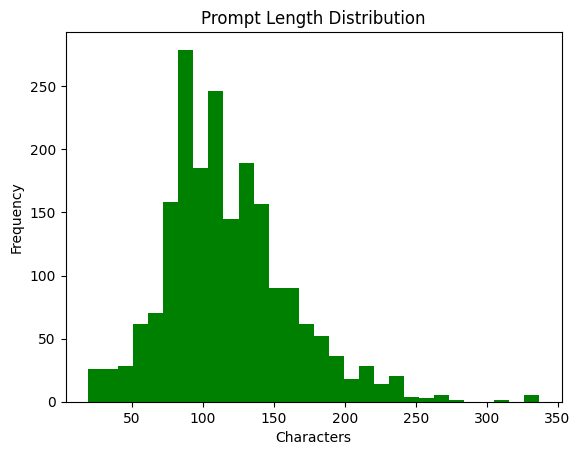

In [15]:
train_data["prompt_length"] = train_data["prompt"].str.len()

plt.hist(train_data["prompt_length"], bins=30, color='g')
plt.title("Prompt Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")
plt.show()

## Option Length Distributions

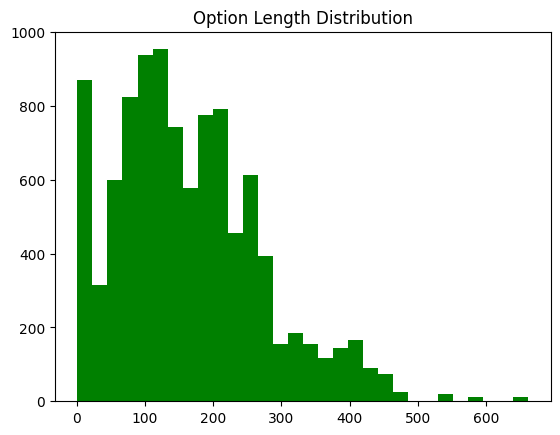

In [16]:
option_lengths = []

for col in ["A","B","C","D","E"]:
    option_lengths.extend(train_df[col].str.len())

plt.hist(option_lengths, bins=30, color='g')
plt.title("Option Length Distribution")
plt.show()

## Prompt vs Option Length Comparison

### 1. Comparison using Box Plot

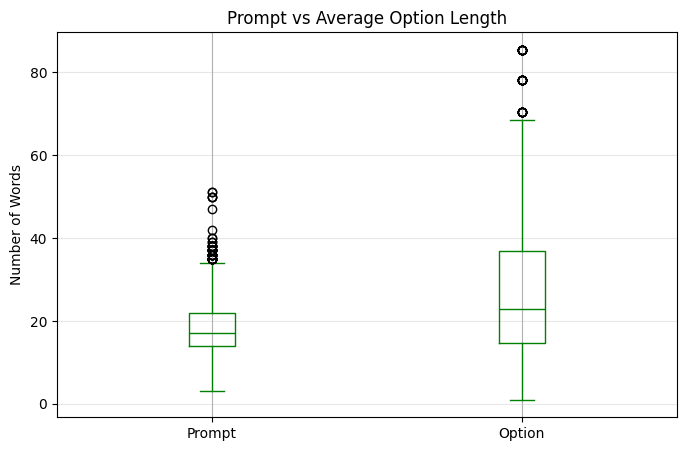

In [18]:
# Prompt word count
train_data["prompt_words"] = (
    train_df["prompt"]
    .astype(str)
    .str.split()
    .str.len()
)

# Average option word count
train_data["option_words"] = (
    train_data[["A","B","C","D","E"]]
    .astype(str)
    .apply(lambda col: col.str.split().str.len())
    .mean(axis=1)
)

comparison = pd.DataFrame({
    "Prompt": train_data["prompt_words"],
    "Option": train_data["option_words"]
})

plt.figure(figsize=(8,5))
comparison.boxplot(color='g')
plt.ylabel("Number of Words")
plt.title("Prompt vs Average Option Length")
plt.grid(axis="y", alpha=0.3)
plt.show()

### 2. Comparison using Distribution Plot

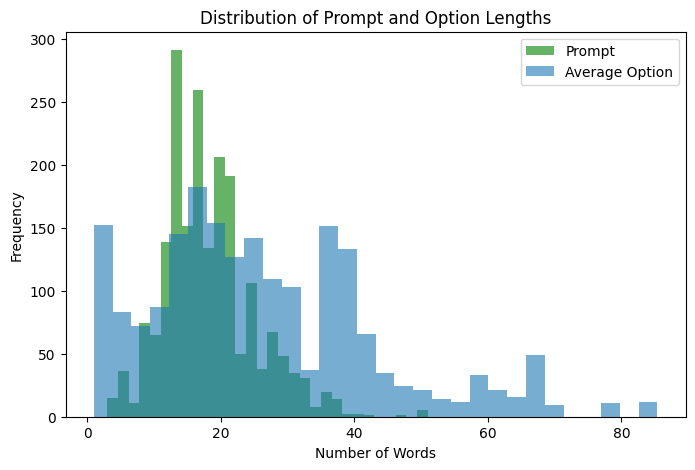

In [21]:
plt.figure(figsize=(8,5))

plt.hist(
    train_data["prompt_words"],
    bins=30,
    alpha=0.6,
    label="Prompt",
    color='g'
)

plt.hist(
    train_data["option_words"],
    bins=30,
    alpha=0.6,
    label="Average Option"
)

plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.title("Distribution of Prompt and Option Lengths")
plt.legend()
plt.show()

## Most Frequent Words in Prompts

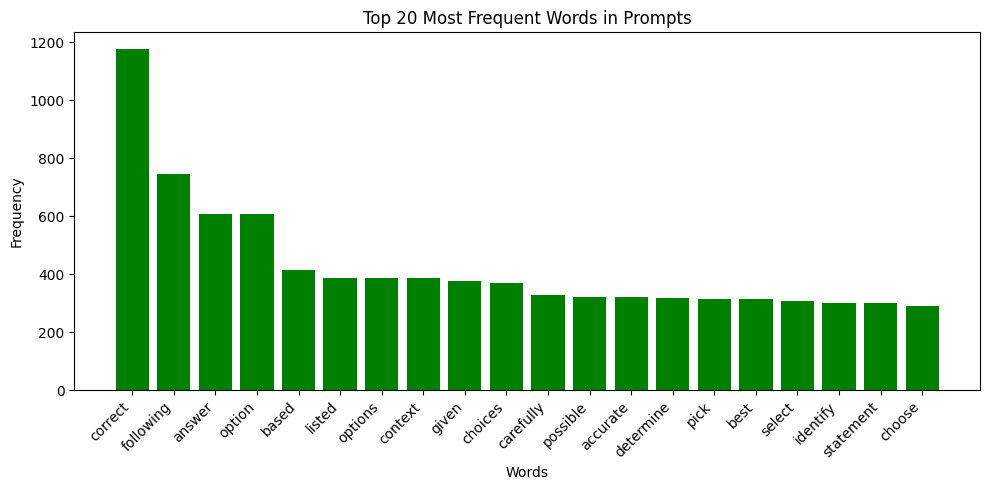

In [27]:
# Combine all prompts
text = " ".join(train_data["prompt"].astype(str))

# Lowercase and tokenize
words = re.findall(r"\b[a-zA-Z]+\b", text.lower())

# Remove stopwords
words = [w for w in words if w not in ENGLISH_STOP_WORDS]

# Count frequencies
word_counts = Counter(words)

# Top 20 words
top_words = word_counts.most_common(20)

# Plot
words, counts = zip(*top_words)

plt.figure(figsize=(10,5))
plt.bar(words, counts, color='g')
plt.xticks(rotation=45, ha="right")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Top 20 Most Frequent Words in Prompts")
plt.tight_layout()
plt.show()

### Word Cloud Visualization

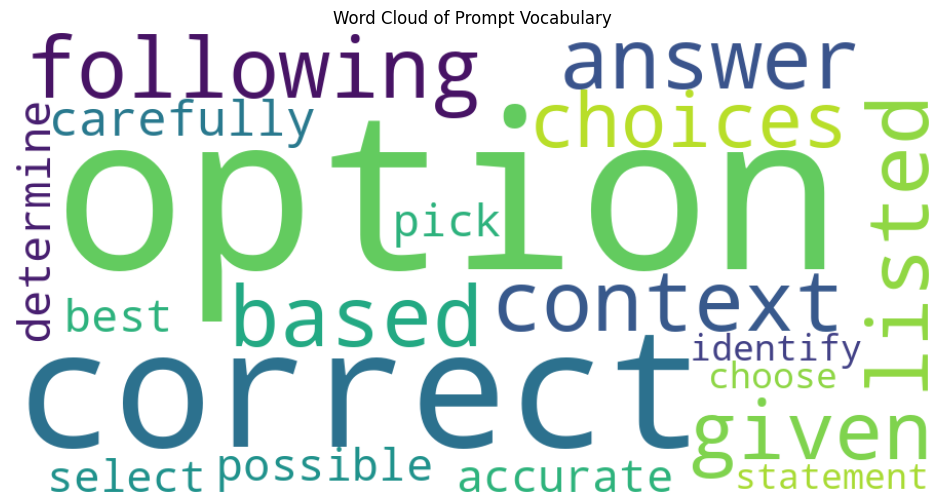

In [26]:
wordcloud = WordCloud(
    width=900,
    height=450,
    background_color="white"
).generate(" ".join(words))

plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Prompt Vocabulary")
plt.show()

# Model 1 : TF-IDF + LightGBM Learning-to-Rank

## Preprocessing

In [14]:
def clean_text(text):
    text = str(text)
    text = text.lower()
    text = text.replace("\n"," ")
    text = " ".join(text.split())
    return text

In [15]:
for col in ["prompt","A","B","C","D","E"]:
    train_data[col] = train_data[col].fillna("").apply(clean_text)
    test_data[col] = test_data[col].fillna("").apply(clean_text)

## Convert MCQ into Ranking Format

In [16]:
options = ["A","B","C","D","E"]

train_rows = []

for _, row in tqdm(train_data.iterrows(), total=len(train_data)):
    
    correct = row["answer"]
    
    for op in options:
        
        train_rows.append({
            "id": row["id"],
            "prompt": row["prompt"],
            "option": row[op],
            "option_label": op,
            "label": int(op == correct)
        })

train_long = pd.DataFrame(train_rows)

print(train_long.shape)

  0%|          | 0/2000 [00:00<?, ?it/s]

(10000, 5)


## Test Ranking Format

In [17]:
test_rows = []

for _, row in tqdm(test_data.iterrows(), total=len(test_data)):
    
    for op in options:
        
        test_rows.append({
            "id": row["id"],
            "option_label": op,
            "prompt": row["prompt"],
            "option": row[op]
        })

test_long = pd.DataFrame(test_rows)

  0%|          | 0/500 [00:00<?, ?it/s]

## Create Additional Features

### Length Features

In [18]:
for df in [train_long, test_long]:
    df["prompt_len"] = df["prompt"].str.len()
    df["option_len"] = df["option"].str.len()
    df["prompt_words"] = df["prompt"].str.split().str.len()
    df["option_words"] = df["option"].str.split().str.len()

In [19]:
num_cols = [
    "prompt_len",
    "option_len",
    "prompt_words",
    "option_words"
]

### Word Overlap and Similarity Feature

In [20]:
def overlap_count(q, a):
    
    q_words = set(q.split())
    a_words = set(a.split())
    
    return len(q_words & a_words)
def overlap_ratio(q, a):

    q_words = set(q.split())
    a_words = set(a.split())

    if len(q_words) == 0:
        return 0

    return len(q_words & a_words) / len(q_words)

In [21]:
for df in [train_long, test_long]:

    df["overlap"] = [
        overlap_count(q, a)
        for q, a in zip(df["prompt"], df["option"])
    ]
    df["overlap_ratio"] = [
    overlap_ratio(q, a)
    for q, a in zip(df["prompt"], df["option"])
    ]

## TF-IDF Feature Engineering

In [22]:
train_text = (
    train_long["prompt"] +
    " [SEP] " +
    train_long["option"]
)

test_text = (
    test_long["prompt"] +
    " [SEP] " +
    test_long["option"]
)

In [23]:
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    stop_words="english"
)

In [24]:
char_vec = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3,6),
    min_df=2,
    max_features=30000
)

In [25]:
X_char_train = char_vec.fit_transform(train_text)
X_char_test = char_vec.transform(test_text)

In [26]:
X_word_train = tfidf.fit_transform(train_text)

X_word_test = tfidf.transform(test_text)

### Add Cosine Similarity

In [27]:
train_prompt_vec = tfidf.transform(train_long["prompt"])
train_option_vec = tfidf.transform(train_long["option"])

test_prompt_vec = tfidf.transform(test_long["prompt"])
test_option_vec = tfidf.transform(test_long["option"])

In [28]:
train_long["cosine_sim"] = [
    cosine_similarity(
        train_prompt_vec[i],
        train_option_vec[i]
    )[0][0]
    for i in range(len(train_long))
]

test_long["cosine_sim"] = [
    cosine_similarity(
        test_prompt_vec[i],
        test_option_vec[i]
    )[0][0]
    for i in range(len(test_long))
]

In [29]:
num_cols.extend([
    "overlap",
    "overlap_ratio",
    "cosine_sim"
])

In [30]:
num_cols

['prompt_len',
 'option_len',
 'prompt_words',
 'option_words',
 'overlap',
 'overlap_ratio',
 'cosine_sim']

In [31]:
question_ids = train_long["id"]

In [32]:
X_num_train = csr_matrix(
    train_long[num_cols].values.astype(np.float32)
)

X_num_test = csr_matrix(
    test_long[num_cols].values.astype(np.float32)
)

In [33]:
X_train = hstack([
    X_word_train,
    X_char_train,
    X_num_train
]).tocsr()

X_test = hstack([
    X_word_test,
    X_char_test,
    X_num_test
]).tocsr()

In [34]:
print(X_word_train.shape)
print(X_char_train.shape)
print(X_num_train.shape)
print(X_train.shape)

(10000, 11244)
(10000, 30000)
(10000, 7)
(10000, 41251)


In [35]:
train_long[num_cols].isnull().sum()

prompt_len       0
option_len       0
prompt_words     0
option_words     0
overlap          0
overlap_ratio    0
cosine_sim       0
dtype: int64

In [36]:
y = train_long["label"]

## LightGBM

In [40]:
def map3_score(df):

    scores = []

    for _, g in df.groupby("id"):

        pred = (
            g.sort_values(
                "oof_pred",
                ascending=False
            )["option_label"]
            .tolist()[:3]
        )

        true = g.loc[
            g["label"] == 1,
            "option_label"
        ].iloc[0]

        if true == pred[0]:
            scores.append(1.0)

        elif true == pred[1]:
            scores.append(0.5)

        elif true == pred[2]:
            scores.append(1/3)

        else:
            scores.append(0)

    return np.mean(scores)

### LGBMClassifier

In [ ]:
lgb_params = {
    "n_estimators":1500,
    "learning_rate":0.03,
    "num_leaves":127,
    "subsample":0.8,
    "colsample_bytree":0.8,
    "objective":"binary",
    "metric":"auc",
    "verbosity":-1,
    "random_state":42
}

#### Initialize Wandb for Model 1 - Classifier

In [ ]:
run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model1_LGBMClassifier_Baseline",
    tags=[
        "Model1",
        "Baseline",
        "TFIDF",
        "LightGBM"
    ],
    config=lgb_params
)

### Train

In [ ]:
gkf = GroupKFold(n_splits=5)

oof = np.zeros(len(train_long))
test_preds = np.zeros(len(test_long))

groups = train_long["id"]

acc_scores = []
f1_scores = []
auc_scores = []
map_scores = []

for fold, (tr_idx, val_idx) in enumerate(
    gkf.split(X_train, y, groups)
):

    print(f"\n========== Fold {fold+1} ==========")

    model = LGBMClassifier(**lgb_params)

    model.fit(
        X_train[tr_idx],
        y.iloc[tr_idx]
    )

    # Validation probabilities
    val_prob = model.predict_proba(
        X_train[val_idx]
    )[:, 1]

    oof[val_idx] = val_prob
    
    fold_df = train_long.iloc[val_idx].copy()
    fold_df["oof_pred"] = val_prob
    
    fold_map = map3_score(fold_df)

    map_scores.append(fold_map)
    
    # Binary predictions
    val_pred = (val_prob >= 0.5).astype(int)

    # Metrics
    acc = accuracy_score(y.iloc[val_idx], val_pred)
    f1 = f1_score(y.iloc[val_idx], val_pred)
    auc = roc_auc_score(y.iloc[val_idx], val_prob)

    acc_scores.append(acc)
    f1_scores.append(f1)
    auc_scores.append(auc)

    print(
        f"Accuracy: {acc:.4f} | "
        f"F1: {f1:.4f} | "
        f"AUC: {auc:.4f}"
    )

    # Log fold metrics
    wandb.log({
        "fold": fold + 1,
        "fold_accuracy": acc,
        "fold_f1": f1,
        "fold_auc": auc,
        "fold_map3": fold_map
    })

    # Test predictions
    test_preds += (
        model.predict_proba(X_test)[:, 1] / gkf.n_splits
    )

In [ ]:
train_long["oof_pred"] = oof
cv_score = map3_score(train_long)

# Log overall CV metrics
wandb.log({
    "cv_accuracy": np.mean(acc_scores),
    "cv_f1": np.mean(f1_scores),
    "cv_auc": np.mean(auc_scores),
    "cv_map3": cv_score,
    "mean_fold_map3": np.mean(map_scores)
})

wandb.summary["Primary Metric"] = cv_score
wandb.summary["Metric Name"] = "CV MAP@3"
wandb.summary["Evaluation Protocol"] = "5-Fold GroupKFold CV"
wandb.summary["CV MAP@3"] = cv_score
wandb.summary["Mean Fold MAP@3"] = np.mean(map_scores)
wandb.summary["Mean Accuracy"] = np.mean(acc_scores)
wandb.summary["Mean F1"] = np.mean(f1_scores)
wandb.summary["Mean ROC AUC"] = np.mean(auc_scores)
wandb.summary["Model"] = "LightGBM Classifier"


print("\nCross Validation Results")
print(f"Mean Accuracy : {np.mean(acc_scores):.4f}")
print(f"Mean F1 Score : {np.mean(f1_scores):.4f}")
print(f"Mean ROC-AUC  : {np.mean(auc_scores):.4f}")
print(f"CV MAP@3 : {cv_score:.6f}")

run.finish()

### LGBMRanker

In [37]:
ranker_params = {
    "objective": "lambdarank",
    "metric": "ndcg",
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 63,
    "force_col_wise": True,
    "verbosity": -1,
    "random_state": 42,
    "n_jobs": -1
}

#### Initialize Wandb for Model 1 - Ranker

In [38]:
run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model1_LGBMRanker_Improved",
    tags=[
        "Model1",
        "Ranker",
        "LightGBM",
        "LearningToRank",
        "TFIDF"
    ],
    config=ranker_params
)

### Training

In [41]:
gkf = GroupKFold(n_splits=5)

groups = train_long["id"]

oof = np.zeros(len(train_long))
test_preds = np.zeros(len(test_long))

fold_scores = []

for fold, (tr_idx, val_idx) in enumerate(
    gkf.split(X_train, y, groups)
):

    print(f"\n========== Fold {fold+1} ==========")

    ranker = LGBMRanker(**ranker_params)

    # Group sizes

    train_groups = (
        train_long.iloc[tr_idx]
        .groupby("id")
        .size()
        .values
    )

    valid_groups = (
        train_long.iloc[val_idx]
        .groupby("id")
        .size()
        .values
    )

    # Train

    ranker.fit(
        X_train[tr_idx],
        y.iloc[tr_idx],
        group=train_groups,
        eval_set=[(X_train[val_idx], y.iloc[val_idx])],
        eval_group=[valid_groups]
    )

    # Validation Predictions

    val_pred = ranker.predict(
        X_train[val_idx]
    )

    oof[val_idx] = val_pred

    # Fold MAP@3

    fold_df = train_long.iloc[val_idx].copy()
    fold_df["oof_pred"] = val_pred

    fold_map = map3_score(fold_df)

    fold_scores.append(fold_map)

    print(f"Fold MAP@3 : {fold_map:.6f}")

    wandb.log({
    "fold": fold + 1,
    "fold_map3": fold_map
    })

    # Test Prediction

    test_preds += (
        ranker.predict(X_test) / gkf.n_splits
    )


Fold 1
Fold MAP@3 : 0.985000

Fold 2
Fold MAP@3 : 0.992500

Fold 3
Fold MAP@3 : 0.993750

Fold 4
Fold MAP@3 : 0.989167

Fold 5
Fold MAP@3 : 0.994583


In [ ]:
# Overall CV Score
train_long["oof_pred"] = oof

cv_score = map3_score(train_long)

print("\nCross Validation Results")
print(f"Mean Fold MAP@3 : {np.mean(fold_scores):.6f}")
print(f"CV MAP@3        : {cv_score:.6f}")


# Log Final Metrics

wandb.log({
    "mean_fold_map3": np.mean(fold_scores),
    "cv_map3": cv_score
})

# Summary

wandb.summary["Primary Metric"] = cv_score
wandb.summary["Metric Name"] = "CV MAP@3"
wandb.summary["Evaluation Protocol"] = "5-Fold GroupKFold CV"
wandb.summary["CV MAP@3"] = cv_score
wandb.summary["Mean Fold MAP@3"] = np.mean(fold_scores)
wandb.summary["Model"] = "LightGBM Ranker"

## Preparing Prediction Probabilities for Ensembling

In [43]:
# Validation probabilities
n_train_questions = len(train_df)

model1_oof_prob = np.zeros((n_train_questions, 5))

for i in range(n_train_questions):

    scores = oof[i*5:(i+1)*5]

    model1_oof_prob[i] = softmax(scores)

print(model1_oof_prob.shape)

# Test probabilities
n_test_questions = len(test_df)

model1_test_prob = np.zeros((n_test_questions,5))

for i in range(n_test_questions):

    scores = test_preds[i*5:(i+1)*5]

    model1_test_prob[i]=softmax(scores)

print(model1_test_prob.shape)

# Save the artficats

np.save("model1_oof_prob.npy",model1_oof_prob)

np.save("model1_test_prob.npy",model1_test_prob)

# Log into W&B
wandb.save("model1_oof_prob.npy")
wandb.save("model1_test_prob.npy")

wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.


(2000, 5)
(500, 5)


['/kaggle/working/wandb/run-20260721_100810-47kticox/files/model1_test_prob.npy']

## Save the artifacts

In [ ]:
import joblib

joblib.dump(
    ranker,
    "lgbm_ranker.pkl"
)

joblib.dump(
    tfidf,
    "word_tfidf.pkl"
)

joblib.dump(
    char_vec,
    "char_tfidf.pkl"
)

## Finish Wandb for Model 1

In [ ]:
model_artifact = wandb.Artifact(
    "lgbm_ranker",
    type="model"
)

model_artifact.add_file("lgbm_ranker.pkl")

wandb.log_artifact(model_artifact)

feature_artifact = wandb.Artifact(
    "tfidf_vectorizers",
    type="feature_extractor"
)

feature_artifact.add_file("word_tfidf.pkl")
feature_artifact.add_file("char_tfidf.pkl")

wandb.log_artifact(feature_artifact)

run.finish()

## Evaluation

In [ ]:
train_long["oof_pred"] = oof

cv_score = map3_score(train_long)

print(f"CV MAP@3 : {cv_score:.6f}")

In [ ]:
example_id = train_long["id"].iloc[0]

display(
    train_long[train_long["id"] == example_id][
        ["option_label", "label", "oof_pred"]
    ].sort_values("oof_pred", ascending=False)
)

## Predictions

In [ ]:
test_long["score"] = test_preds

In [ ]:
test_long.head()

## Submission Data Preparation for Model 1 - TF-IDF + LightGBM Learning-to-Rank

In [ ]:
submission_rows = []

for qid, group in test_long.groupby("id"):
    
    ranked = group.sort_values(
        "score",
        ascending=False
    )
    
    top3 = ranked["option_label"].head(3).tolist()
    
    submission_rows.append({
        "id": qid,
        "prediction": " ".join(top3)
    })

In [ ]:
submission = pd.DataFrame(submission_rows)
submission.head()

In [ ]:
submission.to_csv(
    "submission.csv",
    index=False
)

# Model 2 - DeBERTa

In [44]:
train_data = train_df.copy()
test_data = test_df.copy()

print(train_data.shape)
print(test_data.shape)

(2000, 8)
(500, 7)


In [45]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [46]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


## Encode Labels

In [47]:
label_map = {
    "A":0,
    "B":1,
    "C":2,
    "D":3,
    "E":4
}

train_data["label"] = train_data["answer"].map(label_map)

## Train-Validation Split

In [48]:
train_part, valid_part = train_test_split(
    train_data,
    test_size=0.2,
    stratify=train_data["label"],
    random_state=42
)

## Convert to Hugging Face Dataset

In [49]:
train_ds = Dataset.from_pandas(train_part)
valid_ds = Dataset.from_pandas(valid_part)

test_ds = Dataset.from_pandas(
    test_data.assign(label=0)
)

## Load DeBERTa Tokenizer

In [50]:
MODEL_NAME = "microsoft/deberta-v3-base"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

In [51]:
MAX_LEN = 256

def preprocess(example):

    first_sentences = [
        example["prompt"]
    ] * 5

    second_sentences = [
        example["A"],
        example["B"],
        example["C"],
        example["D"],
        example["E"]
    ]

    tokenized = tokenizer(
        first_sentences,
        second_sentences,
        truncation=True,
        max_length=MAX_LEN
    )

    tokenized["label"] = example["label"]

    return tokenized

In [52]:
train_ds = train_ds.map(preprocess)
valid_ds = valid_ds.map(preprocess)
test_ds = test_ds.map(preprocess)

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [53]:
keep_cols = [
    "input_ids",
    "attention_mask",
    "token_type_ids",
    "label"
]

train_ds = train_ds.remove_columns(
    [c for c in train_ds.column_names if c not in keep_cols]
)

valid_ds = valid_ds.remove_columns(
    [c for c in valid_ds.column_names if c not in keep_cols]
)

test_ds = test_ds.remove_columns(
    [c for c in test_ds.column_names if c not in keep_cols]
)

In [54]:
sample = train_ds[0]

print(type(sample["input_ids"]))
print(len(sample["input_ids"]))
print(train_ds.column_names)

for k,v in sample.items():
    print(k, type(v))

<class 'list'>
5
['label', 'input_ids', 'token_type_ids', 'attention_mask']
label <class 'int'>
input_ids <class 'list'>
token_type_ids <class 'list'>
attention_mask <class 'list'>


## Data Collector

In [55]:
from dataclasses import dataclass
from transformers.tokenization_utils_base import PreTrainedTokenizerBase

@dataclass
class DataCollatorForMultipleChoice:

    tokenizer: PreTrainedTokenizerBase

    def __call__(self, features):

        labels = [f.pop("label") for f in features]

        batch_size = len(features)
        num_choices = len(features[0]["input_ids"])

        flattened = [
            [
                {
                    k: v[i]
                    for k, v in feature.items()
                    if k!= 'label'
                }
                for i in range(num_choices)
            ]
            for feature in features
        ]

        flattened = sum(flattened, [])

        batch = self.tokenizer.pad(
            flattened,
            return_tensors="pt"
        )

        batch = {
            k: v.view(
                batch_size,
                num_choices,
                -1
            )
            for k, v in batch.items()
        }
        if "token_type_ids" in batch:
            del batch["token_type_ids"]
        
        batch["labels"] = torch.tensor(labels)

        return batch

## Load Model

In [56]:
model = AutoModelForMultipleChoice.from_pretrained(
    MODEL_NAME,
    dtype = torch.float32
)

pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/371M [00:00<?, ?B/s]

DebertaV2ForMultipleChoice LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier.weight                

In [57]:
print(next(model.parameters()).dtype)

torch.float32


## Metric

In [58]:
accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    preds = np.argmax(
        logits,
        axis=1
    )

    return accuracy.compute(
        predictions=preds,
        references=labels
    )

## Initialize Wandb for Model 2

In [59]:
run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model2_DeBERTa",
    tags=[
        "Model2",
        "Transformer",
        "DeBERTa",
        "MultipleChoice"
    ],
    config={
        "model": MODEL_NAME,
        "epochs": 4,
        "batch_size": 2,
        "learning_rate": 2e-5,
        "weight_decay": 0.01
    }
)

fold,▁▃▅▆█
fold_map3,▁▆▇▄█
fold,5
fold_map3,0.99458


## Log dataset information before training

In [60]:
wandb.log({
    "Training Samples": len(train_ds),
    "Validation Samples": len(valid_ds),
    "Model": MODEL_NAME
})

## Training Arguments

In [61]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="deberta_mcq",

    report_to = "wandb",

    learning_rate=2e-5,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,

    gradient_accumulation_steps=2,

    num_train_epochs=4,

    fp16=False,

    eval_strategy="epoch",

    save_strategy="epoch",

    load_best_model_at_end=True,

    logging_steps=25,
    
    weight_decay = 0.01
)

In [62]:
collator = DataCollatorForMultipleChoice(
    tokenizer
)

## Trainer

In [63]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    processing_class=tokenizer,
    data_collator=collator,
    compute_metrics=compute_metrics
)

## Train

In [64]:
trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Accuracy
1,6.434833,3.218381,0.247500
2,6.451335,3.218676,0.332500
3,6.450211,3.218020,0.387500
4,6.406694,3.176384,0.437500


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['deberta.embeddings.LayerNorm.weight', 'deberta.embeddings.LayerNorm.bias', 'deberta.encoder.layer.0.attention.output.LayerNorm.weight', 'deberta.encoder.layer.0.attention.output.LayerNorm.bias', 'deberta.encoder.layer.0.output.LayerNorm.weight', 'deberta.encoder.layer.0.output.LayerNorm.bias', 'deberta.encoder.layer.1.attention.output.LayerNorm.weight', 'deberta.encoder.layer.1.attention.output.LayerNorm.bias', 'deberta.encoder.layer.1.output.LayerNorm.weight', 'deberta.encoder.layer.1.output.LayerNorm.bias', 'deberta.encoder.layer.2.attention.output.LayerNorm.weight', 'deberta.encoder.layer.2.attention.output.LayerNorm.bias', 'deberta.encoder.layer.2.output.LayerNorm.weight', 'deberta.encoder.layer.2.output.LayerNorm.bias', 'deberta.encoder.layer.3.attention.output.LayerNorm.weight', 'deberta.encoder.layer.3.attention.output.LayerNorm.bias', 'deberta.encoder.layer.3.output.LayerNorm.weight', 'deberta.encoder.layer.3.output.Laye

TrainOutput(global_step=400, training_loss=6.437123336791992, metrics={'train_runtime': 515.3614, 'train_samples_per_second': 12.418, 'train_steps_per_second': 0.776, 'total_flos': 1599359539195680.0, 'train_loss': 6.437123336791992, 'epoch': 4.0})

## Validation Evaluation

In [65]:
metrics = trainer.evaluate()

wandb.log(metrics)

print(metrics)

{'eval_loss': 3.1763837337493896, 'eval_accuracy': 0.4375, 'eval_runtime': 10.871, 'eval_samples_per_second': 36.795, 'eval_steps_per_second': 4.599, 'epoch': 4.0}


## Compute Validation MAP@3

In [66]:
pred = trainer.predict(valid_ds)

logits = pred.predictions

labels = pred.label_ids

option_labels = np.array(["A", "B", "C", "D", "E"])

top3 = np.argsort(logits, axis=1)[:, ::-1][:, :3]

scores = []

for true, pred_idx in zip(labels, top3):

    ranked = option_labels[pred_idx]
    true_label = option_labels[true]

    if ranked[0] == true_label:
        scores.append(1.0)

    elif ranked[1] == true_label:
        scores.append(0.5)

    elif ranked[2] == true_label:
        scores.append(1/3)

    else:
        scores.append(0)

map3 = np.mean(scores)

print(f"Validation MAP@3 : {map3:.5f}")

wandb.log({
    "Validation MAP@3": map3
})

wandb.summary["Validation MAP@3"] = map3

Validation MAP@3 : 0.60667


## Save the artifacts

In [ ]:
trainer.save_model(
    "/kaggle/working/model2_deberta_v1"
)

tokenizer.save_pretrained(
    "/kaggle/working/model2_deberta_v1"
)

In [ ]:
artifact = wandb.Artifact(
    "model2_deberta_v1",
    type="model"
)

artifact.add_dir("/kaggle/working/model2_deberta_v1")

wandb.log_artifact(artifact)

## Predict Test Logic

In [67]:
preds = trainer.predict(test_ds)

test_logits = preds.predictions

np.save(
    "/kaggle/working/deberta_logits_v1.npy",
    test_logits
)

## Preparing Prediction Probabilities for Ensembling

In [68]:
# Validation Probabilities
model2_oof_prob = softmax(logits, axis=1)

print(model2_oof_prob.shape)

np.save("model2_oof_prob.npy", model2_oof_prob)

# Test Probabilities

model2_test_prob = softmax(test_logits, axis=1)

np.save("model2_test_prob.npy", model2_test_prob)

# Log into W&B
wandb.save("model2_oof_prob.npy")
wandb.save("model2_test_prob.npy")

wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.


(400, 5)


['/kaggle/working/wandb/run-20260721_103651-903jflbc/files/model2_test_prob.npy']

In [69]:
print("train_df shape:", train_df.shape)
print("test_df shape:", test_df.shape)

train_df shape: (2000, 8)
test_df shape: (500, 7)


In [70]:
print("Model 1 OOF:", model1_oof_prob.shape)
print("Model 1 Test:", model1_test_prob.shape)

print("Model 2 OOF:", model2_oof_prob.shape)
print("Model 2 Test:", model2_test_prob.shape)

Model 1 OOF: (2000, 5)
Model 1 Test: (500, 5)
Model 2 OOF: (400, 5)
Model 2 Test: (500, 5)


## Convert Logits to Top-3

In [ ]:
labels = np.array(
    ["A","B","C","D","E"]
)

top3_predictions = []

for row in test_logits:

    idx = np.argsort(row)[::-1][:3]

    top3_predictions.append(
        " ".join(labels[idx])
    )

## Finish Wandb for Model 2

In [ ]:
wandb.summary["Primary Metric"] = map3
wandb.summary["Metric Name"] = "Validation MAP@3"
wandb.summary["Evaluation Protocol"] = "Single Validation Split"
wandb.summary["Validation MAP@3"] = map3
wandb.summary["Validation Accuracy"] = metrics["eval_accuracy"]
wandb.summary["Validation Loss"] = metrics["eval_loss"]
wandb.summary["Model"] = "DeBERTa-v3 Multiple Choice"
run.finish()

## Submission Data Preparation for Model 2 - DeBERTa

In [ ]:
submission = pd.DataFrame({
    "id": test_df["id"],
    "prediction": top3_predictions
})

submission.to_csv(
    "submission.csv",
    index=False
)

submission.head()

# Model 3 — Baseline Retrieval-Augmented Ranking

In [ ]:
train_data = train_df.copy()
test_data = test_df.copy()

print(train_data.shape)
print(test_data.shape)

## Create Knowledge Base

In [ ]:
knowledge = []

for _,row in train_data.iterrows():

    answer_text = row[row["answer"]]

    text = (
        row["prompt"]
        +
        " "
        +
        answer_text
    )

    knowledge.append(text)


len(knowledge)

In [ ]:
TOP_K = 5

## Initialize Wandb for Model 3 - Baseline

In [ ]:
run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model3_RAG_Baseline",
    tags=[
        "Model3",
        "RAG",
        "Baseline",
        "Retriever"
    ],
    config={
        "retriever": "all-MiniLM-L6-v2",
        "reranker": "cross-encoder/ms-marco-MiniLM-L-6-v2",
        "top_k": TOP_K,
        "embedding_model": "SentenceTransformer"
    }
)

In [ ]:
wandb.log({
    "Knowledge Base Size": len(knowledge),
    "Training Questions": len(train_data),
    "Test Questions": len(test_data)
})

## Load Retriever Model

In [ ]:
retriever = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

retriever = retriever.to("cuda")

## Encode Knowledge

In [ ]:
knowledge_embeddings = retriever.encode(
    knowledge,
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)

print(knowledge_embeddings.shape)

In [ ]:
wandb.log({
    "Embedding Dimension": knowledge_embeddings.shape[1]
})

## Build FAISS Vector DB

In [ ]:
dimension = knowledge_embeddings.shape[1]

index = faiss.IndexFlatIP(dimension)

index.add(knowledge_embeddings)

## Retrieve Context

In [ ]:
def retrieve_context(
    question,
    top_k=TOP_K
):

    q_emb = retriever.encode(
        [question],
        normalize_embeddings=True
    )

    scores, ids = index.search(
        q_emb,
        top_k
    )

    contexts = [
        knowledge[i]
        for i in ids[0]
    ]

    return " ".join(contexts)

In [ ]:
# Test Case
retrieve_context(
    test_data.prompt.iloc[0]
)

## Load Cross Encoder

In [ ]:
reranker = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2",
    device="cuda"
)

## Score MCQ Options

In [ ]:
options = [
    "A",
    "B",
    "C",
    "D",
    "E"
]


def predict_question(row):

    context = retrieve_context(
        row["prompt"]
    )

    pairs=[]

    for op in options:

        text = (
            "Context: "
            + context
            +
            " Question: "
            + row["prompt"]
            +
            " Answer: "
            + row[op]
        )

        pairs.append(
            (
                row["prompt"],
                text
            )
        )


    scores = reranker.predict(
        pairs
    )


    order = np.argsort(scores)[::-1]

    prediction = " ".join(
        np.array(options)[order[:3]]
    )

    return prediction

## Generate Submission

In [ ]:
predictions=[]

for _,row in tqdm(
    test_data.iterrows(),
    total=len(test_data)
):

    predictions.append(
        predict_question(row)
    )

In [ ]:
wandb.log({
    "Predictions Generated": len(predictions)
})

## Submission Data Preparation for Model 3 - Baseline Retrieval-Augmented Ranking

In [ ]:
submission = pd.DataFrame(
    {
        "id":test_data.id,
        "prediction":predictions
    }
)


submission.to_csv(
    "submission.csv",
    index=False
)

## Finish Wandb for Model 3 - Baseline

In [ ]:
wandb.summary["Retriever"] = "MiniLM"

wandb.summary["Cross Encoder"] = "MS MARCO MiniLM"

wandb.summary["Knowledge Base Size"] = len(knowledge)

wandb.summary["Model"] = "Baseline RAG"

run.finish()

### Observation

The baseline RAG pipeline improves contextual understanding by retrieving relevant external passages. However, it directly uses the retrieved context without additional engineered ranking features, leaving room for further improvements.

This motivates the enhanced RAG pipeline presented in Model 3 (Improved).

# Model 3 : Improved Retrieval-Augmented Ranking

In [71]:
train_data = train_df.copy()
test_data = test_df.copy()

## Create Long Format 

In [72]:
options = ["A","B","C","D","E"]

train_rows=[]

for _,row in train_data.iterrows():

    for op in options:

        train_rows.append({
            "id": row["id"],
            "prompt": row["prompt"],
            "option": row[op],
            "option_label": op,
            "label": int(op == row["answer"])
        })


train_long = pd.DataFrame(train_rows)

In [73]:
test_rows=[]

for _,row in test_data.iterrows():

    for op in options:

        test_rows.append({
            "id":row["id"],
            "prompt":row["prompt"],
            "option":row[op],
            "option_label":op
        })


test_long=pd.DataFrame(test_rows)

## Clean Prompt for Retrieval

In [74]:
def clean_prompt(text):

    remove = [
        "Pick the best possible answer:",
        "Determine the correct option:",
        "Choose the correct answer:",
        "Select the most accurate option:",
        "Identify the correct statement:"
    ]

    for r in remove:
        text=text.replace(r,"")

    return text.strip()

## Build Knowledge Base

In [75]:
knowledge=[]


for _,row in train_data.iterrows():

    answer_text = row[row["answer"]]

    doc = (
        clean_prompt(row["prompt"])
        +
        " "
        +
        answer_text
    )

    knowledge.append(doc)


knowledge = list(dict.fromkeys(knowledge))

len(knowledge)

1232

In [76]:
TOP_K = 20 # Defining top K documents to fetch

# Defining ranker parameters
ranker_params = {
    "objective": "lambdarank",
    "metric": "map",
    "learning_rate": 0.03,
    "n_estimators": 500,
    "num_leaves": 31,
    "random_state": 42,
    "verbose": -1
} 


## Initialize Wandb for Model 3 - Improved

In [77]:
run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model3_RAG_Improved",
    tags=[
        "Model3",
        "RAG",
        "Improved",
        "LightGBMRanker"
    ],
    config={
        **ranker_params,
        "retriever":"all-MiniLM-L6-v2",
        "cross_encoder":"cross-encoder/ms-marco-MiniLM-L-6-v2",
        "top_k":TOP_K
    }
)

Training Samples,▁
Validation MAP@3,▁
Validation Samples,▁
epoch,▁
eval/accuracy,▁▄▆██
eval/loss,███▁▁
eval/runtime,▁█▆▆▆
eval/samples_per_second,█▁▂▃▃
eval/steps_per_second,█▁▂▃▃
eval_accuracy,▁
+14,...


In [78]:
wandb.log({
    "Knowledge Base Size": len(knowledge),
    "Training Questions": train_data.shape[0],
    "Test Questions": test_data.shape[0]
})

## Create FAISS Vector DB

### Retriever

In [79]:
retriever = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cuda"
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (3 outputs left out)

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

### Encode KB:

In [80]:
kb_embeddings = retriever.encode(
    knowledge,
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=True
)

Batches:   0%|          | 0/20 [00:00<?, ?it/s]

In [81]:
wandb.log({
    "Embedding Dimension": kb_embeddings.shape[1]
})

### Build FAISS

In [82]:
dim = kb_embeddings.shape[1]

index = faiss.IndexFlatIP(dim)

index.add(kb_embeddings)

## Retrieve Top 20

In [83]:
def retrieve_docs(question, k=TOP_K):

    emb = retriever.encode(
        [clean_prompt(question)],
        normalize_embeddings=True
    )

    scores, ids = index.search(
        emb,
        k
    )

    return [
        knowledge[i]
        for i in ids[0]
    ]

## Cross Encoder Reranking

In [84]:
reranker = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2",
    device="cuda"
)

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

In [85]:
def get_best_context(question):

    docs = retrieve_docs(question)

    pairs = [
        [
            clean_prompt(question),
            doc
        ]
        for doc in docs
    ]

    scores = reranker.predict(pairs)

    best = np.argmax(scores)

    return docs[best]

## Generate Contexts Once

In [86]:
train_context={}

for qid,prompt in tqdm(
    zip(train_data.id, train_data.prompt),
    total=len(train_data)
):

    train_context[qid] = get_best_context(prompt)

  0%|          | 0/2000 [00:00<?, ?it/s]

In [87]:
test_context={}

for qid,prompt in tqdm(
    zip(test_data.id, test_data.prompt),
    total=len(test_data)
):

    test_context[qid] = get_best_context(prompt)

  0%|          | 0/500 [00:00<?, ?it/s]

In [88]:
train_long["context"] = (
    train_long["id"].map(train_context)
)

test_long["context"] = (
    test_long["id"].map(test_context)
)

## Create RAG Text Features

In [89]:
train_text = (
    train_long.context
    +
    " [SEP] "
    +
    train_long.prompt
    +
    " [SEP] "
    +
    train_long.option
)


test_text = (
    test_long.context
    +
    " [SEP] "
    +
    test_long.prompt
    +
    " [SEP] "
    +
    test_long.option
)

## TF-IDF + Char Features

In [90]:
word_vec = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1,2)
)

char_vec = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3,5),
    max_features=15000
)

X_word_train = word_vec.fit_transform(train_text)
X_word_test = word_vec.transform(test_text)


X_char_train = char_vec.fit_transform(train_text)
X_char_test = char_vec.transform(test_text)

## Add RAG Numerical Features

In [91]:
def overlap(a,b):

    a=set(a.lower().split())
    b=set(b.lower().split())

    return len(a & b)

In [92]:
for df in [train_long,test_long]:

    df["context_overlap"] = df.apply(
        lambda x:
        overlap(
            x.context,
            x.option
        ),
        axis=1
    )


    df["option_len"] = (
        df.option.str.len()
    )

In [93]:
num_cols=[
    "context_overlap",
    "option_len"
]

X_num_train=csr_matrix(
    train_long[num_cols]
)

X_num_test=csr_matrix(
    test_long[num_cols]
)

## Final Matrix

In [94]:
X_train=hstack([
    X_word_train,
    X_char_train,
    X_num_train
]).tocsr()


X_test=hstack([
    X_word_test,
    X_char_test,
    X_num_test
]).tocsr()

## Train LGBMRanker

In [95]:
def map3_score(df):

    scores = []

    for _, g in df.groupby("id"):

        pred = (
            g.sort_values(
                "oof_pred",
                ascending=False
            )["option_label"]
            .tolist()[:3]
        )

        true = g.loc[
            g["label"] == 1,
            "option_label"
        ].iloc[0]

        if true == pred[0]:
            scores.append(1.0)
        elif true == pred[1]:
            scores.append(0.5)
        elif true == pred[2]:
            scores.append(1/3)
        else:
            scores.append(0.0)

    return np.mean(scores)

In [96]:
groups = train_long.id
y = train_long.label

oof = np.zeros(len(train_long))
test_preds = np.zeros(len(test_long))

gkf = GroupKFold(n_splits=5)

fold_scores = []

for fold, (tr, val) in enumerate(
    gkf.split(X_train, y, groups)
):

    print(f"\n========== Fold {fold+1} ==========")

    model = LGBMRanker(**ranker_params)

    train_group = (
        train_long.iloc[tr]
        .groupby("id")
        .size()
        .values
    )

    model.fit(
        X_train[tr],
        y.iloc[tr],
        group=train_group
    )

    # Validation predictions
    oof[val] = model.predict(X_train[val])

    # Test predictions
    test_preds += model.predict(X_test) / gkf.n_splits

    # Validation MAP@3
    fold_df = train_long.iloc[val].copy()
    fold_df["oof_pred"] = oof[val]

    fold_map = map3_score(fold_df)

    fold_scores.append(fold_map)

    print(f"Fold {fold+1} MAP@3 : {fold_map:.5f}")

    # ---------------------------
    # W&B Fold Logging
    # ---------------------------
    wandb.log({
    "fold": fold + 1,
    "fold_map3": fold_map
    })


========== Fold 1 ==========
Fold 1 MAP@3 : 0.99625

========== Fold 2 ==========
Fold 2 MAP@3 : 0.99875

========== Fold 3 ==========
Fold 3 MAP@3 : 0.99625

========== Fold 4 ==========
Fold 4 MAP@3 : 0.99750

========== Fold 5 ==========
Fold 5 MAP@3 : 0.99875


In [97]:
train_long["oof_pred"] = oof

cv_score = map3_score(train_long)

print("\n========== Cross Validation ==========")
print(f"Mean Fold MAP@3 : {np.mean(fold_scores):.5f}")
print(f"CV MAP@3        : {cv_score:.5f}")

# W&B Final Metrics

wandb.log({
    "mean_fold_map3": np.mean(fold_scores),
    "cv_map3": cv_score
})

# W&B Summary

wandb.summary["Primary Metric"] = cv_score
wandb.summary["Metric Name"] = "CV MAP@3"
wandb.summary["Evaluation Protocol"] = "5-Fold GroupKFold CV"
wandb.summary["CV MAP@3"] = cv_score
wandb.summary["Mean Fold MAP@3"] = np.mean(fold_scores)

wandb.summary["Model"] = "RAG + LightGBM Ranker"
wandb.summary["Retriever"] = "all-MiniLM-L6-v2"
wandb.summary["Cross Encoder"] = "cross-encoder/ms-marco-MiniLM-L-6-v2"
wandb.summary["Top K"] = TOP_K


========== Cross Validation ==========
Mean Fold MAP@3 : 0.99750
CV MAP@3        : 0.99750


## Preparing Prediction Probabilities for Ensembling

In [98]:
# Validation probabilities

n_train_questions = len(train_df)

model3_oof_prob = np.zeros((n_train_questions, 5))

for i in range(n_train_questions):
    scores = oof[i*5:(i+1)*5]
    model3_oof_prob[i] = softmax(scores)

np.save("model3_oof_prob.npy", model3_oof_prob)


# Test probabilities

n_test_questions = len(test_df)

model3_test_prob = np.zeros((n_test_questions, 5))

for i in range(n_test_questions):
    scores = test_preds[i*5:(i+1)*5]
    model3_test_prob[i] = softmax(scores)

np.save("model3_test_prob.npy", model3_test_prob)

# Log into W&B
wandb.save("model3_oof_prob.npy")
wandb.save("model3_test_prob.npy")

wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.


['/kaggle/working/wandb/run-20260721_110059-icjoyr8y/files/model3_test_prob.npy']

## Finish Wandb for Model 3 - Improved

In [ ]:
joblib.dump(model, "rag_ranker.pkl")

artifact = wandb.Artifact(
    "rag_ranker",
    type="model"
)

artifact.add_file("rag_ranker.pkl")

wandb.log_artifact(artifact)


# Finish W&B Run

run.finish()

## Submission Data Preparation for Model 3 -  Improved Retrieval-Augmented Ranking

In [ ]:
test_long["score"]=test_preds

submission = (
    test_long
    .sort_values(
        ["id","score"],
        ascending=[True,False]
    )
    .groupby("id")
    .option_label
    .apply(
        lambda x:
        " ".join(
            x.head(3)
        )
    )
    .reset_index()
)

## Submission for Model 3 - Improved Retrieval-Augmented Ranking

In [ ]:
submission.columns=[
    "id",
    "prediction"
]

submission.to_csv(
    "submission.csv",
    index=False
)

# Model 4 - Weighted Ensemble

## Weight Selection for previous models

In [99]:
# Weights selected based on individual model performance
w1 = 0.35      # Model 1
w2 = 0.20      # DeBERTa
w3 = 0.45      # RAG Ranker

ensemble_test_prob = (
    w1 * model1_test_prob +
    w2 * model2_test_prob +
    w3 * model3_test_prob
)

## Initialize Wandb for Model 4

In [ ]:
ensemble_params = {
    "ensemble_method": "Weighted Average",
    "model1_weight": 0.35,
    "model2_weight": 0.20,
    "model3_weight": 0.45,
    "model1_score": 0.7550,
    "model2_score": 0.7303,
    "model3_score": 0.7610,
}

run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model4_Weighted_Ensemble",
    tags=[
        "Model4",
        "Ensemble",
        "WeightedAverage",
        "FinalModel"
    ],
    config=ensemble_params
)

## Calculationg Top-3 predictions

In [100]:
option_labels = np.array(["A","B","C","D","E"])

top3 = np.argsort(
    ensemble_test_prob,
    axis=1
)[:, ::-1][:,:3]

predictions = [
    " ".join(option_labels[idx])
    for idx in top3
]

## Submission Data Preparation for Model 4 - Weighted Ensemble

In [101]:
submission = pd.DataFrame({
    "id": test_df["id"],
    "prediction": predictions
})

submission.head()

,id,prediction
0,1,A B C
1,2,B D E
2,3,B E C
3,4,E C A
4,5,C D A


In [102]:
submission.to_csv(
    "submission_ensemble.csv",
    index=False
)

## Finish Wandb for Model 4

In [ ]:
wandb.log({
    "model1_weight": 0.35,
    "model2_weight": 0.20,
    "model3_weight": 0.45,
})
wandb.save("submission_ensemble.csv")
wandb.finish()

# Appendix

## Milestone 1

In [ ]:
import numpy as np
import pandas as pd
import string
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
train_data = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')

In [ ]:
print(f"Columns of the train dataset : {train_data.columns}")

1. Calculate the frequency distribution of the correct  answer  (A, B, C, D, E) in train.csv. Based on your counts, what is the sum of the occurrences of the most frequent option and the least frequent option?

In [ ]:
answer_counts = train_data['answer'].value_counts()
print("Frequency Distribution of the correct answers : \n", answer_counts)

result = answer_counts.max() + answer_counts.min()
print("The sum of the occurrences of the most frequent \
option and the least frequent option:", result)

2. After converting the prompt column to lowercase and removing all standard punctuation characters (using Python's string.punctuation), split the text by whitespace. What is the total number of unique words (vocabulary size) across the entire cleaned prompt column of train.csv?  

In [ ]:
translator = str.maketrans('', '', string.punctuation)

clean_prompts = (
    train_data['prompt']
    .fillna('')
    .str.lower()
    .str.translate(translator)
)

vocab = set()

for text in clean_prompts:
    vocab.update(text.split())

print(f"Total number of unique words (vocabulary size) across \
the entire cleaned prompt column : {len(vocab)}")

3. Using the cleaned prompt from Row ID 1, filter out the standard English stop words using sklearn.feature_extraction.text.ENGLISH_STOP_WORDS. How many words are left in the prompt for Row ID 1 after filtering?

In [ ]:
train_data.head()

In [ ]:
display(train_data[train_data['id']==1])
stop_words  = set(ENGLISH_STOP_WORDS)
words = clean_prompts[0].split()

filtered_words = [word for word in words if word not in stop_words]
print(f"Before filtering words : {words}")
print(f"Filtered Words : {filtered_words}")
print(f"Words are left in the prompt for Row ID 1 after filtering : {len(filtered_words)}")

4. Fit a default TfidfVectorizer(stop_words='english') on a list containing all the combined text of the prompts and options in train.csv. What is the exact total number of feature columns (vocabulary size) generated by the vectorizer?  

In [ ]:
combined_text = (
    train_data['prompt'].fillna('') + ' ' +
    train_data['A'].fillna('') + ' ' +
    train_data['B'].fillna('') + ' ' +
    train_data['C'].fillna('') + ' ' +
    train_data['D'].fillna('') + ' ' +
    train_data['E'].fillna('')
)

vectorizer = TfidfVectorizer(stop_words='english')

X = vectorizer.fit_transform(combined_text)

vocab_size = len(vectorizer.vocabulary_)

print("Vocabulary size:", vocab_size)

5. Using the TF-IDF vectorizer fitted in Question 3, calculate the cosine similarity between the prompt and option A strictly for Row ID 1. What is the resulting similarity score? (Round to 4 decimal places).  

In [ ]:
# Row with id = 1
row = train_data[train_data['id'] == 1].iloc[0]

prompt = row['prompt']
option_a = row['A']

# Used the vectorizer already fitted in Q4
prompt_vec = vectorizer.transform([prompt])
option_a_vec = vectorizer.transform([option_a])

similarity = cosine_similarity(prompt_vec, option_a_vec)[0][0]

print(round(similarity, 4))

6. Expand the logic from Question 4: For every row in train.csv, calculate the cosine similarity between the prompt and each of its 5 options .  Then calculate the percentage of instances where the option with the highest cosine similarity matches the correct answer.

In [ ]:
predictions = []

for _, row in train_data.iterrows():

    texts = [row['prompt'], row['A'], row['B'], row['C'], row['D'], row['E']]
    vectors = vectorizer.transform(texts)
    prompt_vec = vectors[0]
    option_vecs = vectors[1:]

    sims = cosine_similarity(prompt_vec, option_vecs)[0]

    predicted = ['A', 'B', 'C', 'D', 'E'][np.argmax(sims)]
    predictions.append(predicted)
   

accuracy = (train_data['answer'] == predictions).mean() * 100

print(f"Accuracy = {accuracy:.2f}%")

7. If the ground truth answer for a question is C, what is the MAP@3 score if a model predicts C A B?  

In [ ]:
def find_MAP(truth,pred):
    score = 0
    if truth == pred[0]:
        score = 1.0
    elif truth == pred[1]:
        score = 1/2
    elif truth == pred[2]:
        score = 1/3
    return score

In [ ]:
truth = 'C'
pred = ['C','A','B']
print(f"MAP@3 is : {find_MAP(truth,pred)}")

8. If the ground truth answer for a question is  B, what is the MAP@3 score if a model predicts D B E? 

In [ ]:
def find_MAP(truth,pred):
    score = 0
    if truth == pred[0]:
        score = 1.0
    elif truth == pred[1]:
        score = 1/2
    elif truth == pred[2]:
        score = 1/3
    return score

In [ ]:
truth = 'B'
pred = ['D','B','E']
print(f"MAP@3 is : {find_MAP(truth,pred)}")

9. The Majority Class Baseline: Find the most frequent correct answer in the training set (using your data from Q1). Make a static prediction for every single row where that most frequent answer is your 1st guess, followed by the second most frequent, and then the third most frequent. What is the overall MAP@3 score of this "Majority Class" baseline on train.csv?

In [ ]:
answer_counts = train_data['answer'].value_counts()

print("Answer Frequency Distribution : ")
print(answer_counts)

top3 = answer_counts.index[:3].tolist()

print("Top 3 Answers : ")
print(top3)

def apk(actual, predicted, k=3):
    predicted = predicted[:k]

    if actual in predicted:
        return 1.0 / (predicted.index(actual) + 1)

    return 0.0

map3 = train_data['answer'].apply(
    lambda x: apk(x, top3)
).mean()

print(f"Majority Class Baseline MAP@3 = {map3:.3f}")

10. The TF-IDF Pipeline: Build a basic pipeline that evaluates every row in train.csv. For each row, calculate the TF-IDF cosine similarity between the prompt and each of the 5 options. Sort these options from highest similarity to lowest to form your top 3 predictions. What is the final average MAP@3 score of this TF-IDF pipeline across the entire training set?  

In [ ]:
def apk(actual, predicted, k=3):
    predicted = predicted[:k]

    if actual in predicted:
        return 1.0 / (predicted.index(actual) + 1)

    return 0.0

scores = []

for _, row in train_data.iterrows():

    prompt_vec = vectorizer.transform([row['prompt']])

    similarities = {}

    for option in ['A', 'B', 'C', 'D', 'E']:
        option_vec = vectorizer.transform([row[option]])
        similarities[option] = cosine_similarity(
            prompt_vec,
            option_vec
        )[0][0]

    ranked_options = sorted(
        similarities,
        key=similarities.get,
        reverse=True
    )

    top3 = ranked_options[:3]

    scores.append(
        apk(row['answer'], top3)
    )

map3 = np.mean(scores)

print(f"MAP@3 = {map3:.3f}")

## Milestone 2 

In [ ]:
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from transformers import AutoTokenizer, AutoModel, AutoModelForSeq2SeqLM
from sentence_transformers import SentenceTransformer, util
from transformers import pipeline
import torch

1. Load train.csv using the Hugging Face datasets library (do not use pandas). Use the .map() function to create a new column called combined_text that concatenates the prompt and A columns with a space in between. E.g., prompt_text A_text. What is the exact character length (total number of string characters using Python's len() function, NOT the number of tokens) of the combined_text string for the row at index 51? Note: We follow zero-indexing here.

In [ ]:
# Load CSV (no pandas)
dataset = load_dataset("csv", data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")["train"]
print(dataset)
# Create combined_text = prompt + " " + A
dataset = dataset.map(
    lambda x: {"combined_text": x["prompt"] + " " + x["A"]}
)

# Character length of row at index 51
length = len(dataset[51]["combined_text"])

print(f"Exact character length of the combined_text string \
for the row at index 51 : {length}")

2. Initialize the bert-base-uncased tokenizer. Look at the tokenizer's configuration properties: what is the exact total vocabulary size (the maximum number of unique subword tokens the model knows) hardcoded into this tokenizer? 

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

print(f"Exact total vocabulary size (the maximum number of unique subword \
tokens the model knows) hardcoded into this tokenizer : {tokenizer.vocab_size}")

3. Transformers rely on special tokens to understand sentence boundaries. Using the bert-base-uncased tokenizer from the previous step, extract the exact integer ID assigned to the [SEP] (Separator) token.  

In [ ]:
print(f"Exact integer ID assigned to the \
[SEP] : {tokenizer.sep_token_id}")

4. Using the bert-base-uncased tokenizer, tokenize the entire prompt column of the train dataset simultaneously. Set padding='max_length', truncation=True, max_length=128, and return_tensors='pt' (PyTorch tensors). 

What is the exact geometric shape (dimensions) of the resulting input_ids tensor?

In [ ]:
encoded = tokenizer(
                   list(dataset["prompt"]),
                   padding='max_length',
                   truncation=True, 
                   max_length=128,
                   return_tensors='pt')
print(f"Exact geometric shape (dimensions) of the resulting \
input_ids tensor : {encoded["input_ids"].shape}")

5. A standard bert-base-uncased model has a hidden embedding size of 768 dimensions and uses exactly 12 attention heads in each layer. 

    In Transformer architecture, the hidden size is divided equally among the attention heads. What is the exact dimensionality (size) of each individual attention head?  

In [ ]:
hidden_embedding_size = 768
attention_heads = 12
# Attention head is divided equally among the attention heads
individual_attention_head_size = hidden_embedding_size//attention_heads
print(f"Eexact dimensionality (size) of each individual \
attention head : {individual_attention_head_size}")

6.Load the bert-base-uncased model using AutoModel.from_pretrained(). Tokenize the prompt from row ID 0 using the tokenizer's default settings (do not apply any manual padding or truncation). Pass this tokenized input through the model. Look at the output object. 

What is the exact shape of the last_hidden_state tensor returned? 

Note: We follow zero-indexing here.

In [ ]:
# Load tokenizer and model
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModel.from_pretrained("bert-base-uncased")

# Row index 0 prompt
text = dataset[0]["prompt"]

# Default tokenization (no padding/truncation)
inputs = tokenizer(
    text,
    return_tensors="pt"
)

# Forward pass
outputs = model(**inputs)

print(f"Exact shape of the last_hidden_state tensor \
returned : {outputs.last_hidden_state.shape}")

7. Using the last_hidden_state tensor from the previous question, extract the embedding vector representing the [CLS] token (which is always the token at index 0). What is the sum of the first 5 float values in this [CLS] vector? (Round your answer to 4 decimal places).  

In [ ]:
cls_embedding = outputs.last_hidden_state[0, 0, :]

# first 5 values
first_5 = cls_embedding[:5]

print(first_5)

# sum and round
answer = round(first_5.sum().item(), 4)

print(f"Sum of the first 5 float values in \
this [CLS] vector : {answer}")

8. Load bert-base-uncased with the parameter output_attentions=True. Tokenize the exact string "Light-ion fusion is a technique." (ensuring you set return_tensors='pt') and pass it through the model. Extract the attention matrix for the last layer (index -1) and the first attention head (head index 0).

   What is the exact attention weight (a float value) that the [CLS] token (token index 0) pays to the word fusion (you will need to find the specific token index for fusion in the input_ids)? (Round your answer to 4 decimal places).  

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

model = AutoModel.from_pretrained(
    "bert-base-uncased",
    output_attentions=True
)

text = "Light-ion fusion is a technique."

inputs = tokenizer(
    text,
    return_tensors="pt"
)

# Check tokens
tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

print(tokens)

# Find fusion index
fusion_idx = tokens.index("fusion")

print("fusion index:", fusion_idx)

with torch.no_grad():
    outputs = model(**inputs)

# last layer attention
last_attention = outputs.attentions[-1]

print(last_attention.shape)

# batch 0, head 0, CLS token attention to fusion
attention_value = last_attention[0, 0, 0, fusion_idx]

answer = round(attention_value.item(), 4)

print(f"Exact attention weight (a float value) \
that the [CLS] token (token index 0) pays to the word fusion : {answer}")

9. Initialize the sentence-transformers/all-MiniLM-L6-v2 model. Use the model's .encode() method to generate embeddings for both the prompt and Option B for row ID 0. Calculate the cosine similarity between these two vectors specifically using the sentence_transformers.util.cos_sim() function. What is the resulting similarity score rounded to 4 decimal places? Note: We follow zero-indexing here.

In [ ]:
# Load dataset (no pandas)
dataset = load_dataset("csv", data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")["train"]

# Initialize model
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Get row ID 0
prompt_text = dataset[0]["prompt"]
option_b_text = dataset[0]["B"]

# Generate embeddings
prompt_embedding = model.encode(prompt_text)
option_b_embedding = model.encode(option_b_text)

# Cosine similarity using sentence_transformers.util.cos_sim()
similarity = util.cos_sim(
    prompt_embedding,
    option_b_embedding
)

answer = round(similarity.item(), 4)

print(f"The resulting similarity score : {answer}")

10. Build two complete ranking pipelines evaluating every row in train.csv.

    Pipeline 1: Use the TF-IDF cosine similarity approach from Milestone 1.
    
    Pipeline 2: Use the sentence-transformers/all-MiniLM-L6-v2 model to generate embeddings for the prompt and all five options. Rank options using cosine similarity to form Top-3 predictions.
    
    First, what is the final MAP@3 score of the all-MiniLM-L6-v2 pipeline across the entire training set? 
    
    Second, count the number of questions for which the correct answer is NOT present in the TF-IDF Top-3 predictions BUT IS present in the MiniLM Top-3 predictions. What is this exact resulting count?  

In [ ]:
# Load data


dataset = load_dataset(
    "csv",
    data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
)["train"]


options = ["A", "B", "C", "D", "E"]


# MAP@3 function


def apk(actual, predicted, k=3):
    predicted = predicted[:k]

    if actual in predicted:
        return 1 / (predicted.index(actual) + 1)

    return 0


def map3(actuals, predictions):
    scores = []

    for actual, pred in zip(actuals, predictions):
        scores.append(apk(actual, pred))

    return np.mean(scores)




# Pipeline 1: TF-IDF cosine similarity


all_text = []

for row in dataset:
    all_text.append(row["prompt"])
    
    for op in options:
        all_text.append(row[op])


tfidf = TfidfVectorizer()

tfidf.fit(all_text)


tfidf_predictions = []


for row in dataset:

    prompt_vec = tfidf.transform(
        [row["prompt"]]
    )

    sims = {}

    for op in options:

        option_vec = tfidf.transform(
            [row[op]]
        )

        sims[op] = cosine_similarity(
            prompt_vec,
            option_vec
        )[0][0]


    ranked = sorted(
        sims,
        key=sims.get,
        reverse=True
    )

    tfidf_predictions.append(
        ranked[:3]
    )



# Pipeline 2: MiniLM embeddings


model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)


minilm_predictions = []


for row in dataset:

    prompt_embedding = model.encode(
        row["prompt"],
        convert_to_tensor=True
    )

    option_texts = [
        row[o] for o in options
    ]

    option_embeddings = model.encode(
        option_texts,
        convert_to_tensor=True
    )


    similarities = util.cos_sim(
        prompt_embedding,
        option_embeddings
    )[0]


    top_indices = similarities.argsort(
        descending=True
    )


    ranked_options = [
        options[i]
        for i in top_indices
    ]


    minilm_predictions.append(
        ranked_options[:3]
    )



# Results


answers = dataset["answer"]


minilm_map3 = map3(
    answers,
    minilm_predictions
)


print(
    "MiniLM MAP@3:",
    round(minilm_map3, 3)
)



# Count questions fixed by MiniLM

fixed_count = 0


for actual, tfidf_pred, mini_pred in zip(
    answers,
    tfidf_predictions,
    minilm_predictions
):

    if (
        actual not in tfidf_pred
        and actual in mini_pred
    ):
        fixed_count += 1


print(
    "TF-IDF missed but MiniLM got:",
    fixed_count
)

11. Initialize the Hugging Face pipeline for "zero-shot-classification" (it will default to facebook/bart-large-mnli). For the prompt of the 2nd row (index 1), pass Options A, B, and C as the candidate_labels. What is the probability score given to the top-ranked option? (Round to 4 decimal places).

In [ ]:
# Load train.csv
dataset = load_dataset(
    "csv",
    data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
)["train"]


# Initialize zero-shot pipeline
classifier = pipeline(
    "zero-shot-classification"
)


# Row index 1 (2nd row)
prompt_text = dataset[1]["prompt"]

candidate_labels = [
    dataset[1]["A"],
    dataset[1]["B"],
    dataset[1]["C"]
]


# Prediction
result = classifier(
    prompt_text,
    candidate_labels
)


print(result)


# Top ranked probability score
top_score = result["scores"][0]

print(f"The probability score given to the top-ranked\
option : {round(top_score, 4)}")

12. Run the exact same zero-shot classification as the previous question, but this time pass the argument multi_label=True. 

    What is the absolute difference between the sum of the 3 probabilities in the previous question (which uses Softmax) and the sum of the 3 probabilities in this question (which uses independent Sigmoids)?

In [ ]:
classifier = pipeline(
    "zero-shot-classification"
)


prompt_text = dataset[1]["prompt"]

candidate_labels = [
    dataset[1]["A"],
    dataset[1]["B"],
    dataset[1]["C"]
]


# -----------------------------
# Softmax (previous question)
# -----------------------------

softmax_result = classifier(
    prompt_text,
    candidate_labels
)

softmax_sum = sum(
    softmax_result["scores"]
)



# Independent Sigmoid

sigmoid_result = classifier(
    prompt_text,
    candidate_labels,
    multi_label=True
)

sigmoid_sum = sum(
    sigmoid_result["scores"]
)


# Difference

difference = abs(
    softmax_sum - sigmoid_sum
)

print("Softmax scores:", softmax_result["scores"])
print("Softmax sum:", softmax_sum)

print("Sigmoid scores:", sigmoid_result["scores"])
print("Sigmoid sum:", sigmoid_sum)

print("Difference:", round(difference, 4))

13. Let's try Generative AI instead of Classification. 

    Load a Small Language Model like google/flan-t5-small using the Hugging Face pipeline("text2text-generation"). Construct the following exact string for row index 0: "Question: [prompt]. Is the correct answer A: [A] or B: [B]? Answer with just the letter A or B." 
    Pass this string to the pipeline, setting max_new_tokens=5. What is the exact string output returned by the model? 

In [ ]:
# Load FLAN-T5
tokenizer = AutoTokenizer.from_pretrained(
    "google/flan-t5-small"
)

model = AutoModelForSeq2SeqLM.from_pretrained(
    "google/flan-t5-small"
)

# Row index 0
row = dataset[0]

prompt = (
    f"Question: {row['prompt']}. "
    f"Is the correct answer A: {row['A']} or B: {row['B']}? "
    f"Answer with just the letter A or B."
)

# Tokenize
inputs = tokenizer(
    prompt,
    return_tensors="pt"
)

# Generate
with torch.no_grad():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=5
    )

# Decode
generated_text = tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
)

print("The exact string output returned by the model:", generated_text)